# 03 · Modelado supervisado — Bike Sharing Demand

**Responsable de este notebook:** Joan · **Plan:** `project_plan_crisp_dm.md` §6 · Pardo y José entregan sus modelos en `03b_ridge.ipynb` y `03c_random_forest.ipynb`; Joan consolida la tabla.

**Contenido actual (Sprint 1):** sección de **baselines** (§6.1). La sección de LightGBM, el tuning y los extras se agregan en el Sprint 2.

**Protocolo:** todo con **train** (2011-01-01 a 2012-06-30) y `TimeSeriesSplit` (ventana expansiva, 5 folds). El test (jul–dic 2012) **no se usa** en este notebook. Métrica de decisión: **RMSLE**.


## 1) Preparación del entorno

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "config" / "config.py").exists():
        RAIZ = _p
        break
else:
    raise FileNotFoundError("No se encontró config/config.py")
sys.path.insert(0, str(RAIZ))

from config.config import CONFIG, RANDOM_STATE
from src.data_loader import load_data, temporal_split, separar_xy
from src.evaluate import rmsle, evaluar_pipeline, get_cv, validar_temporal

sns.set_theme(style="whitegrid")
FIG_DIR = CONFIG["dir_reports"] / "joan" / "figuras"; FIG_DIR.mkdir(parents=True, exist_ok=True)
print("RANDOM_STATE =", RANDOM_STATE, "| CV:", CONFIG["cv"])

RANDOM_STATE = 42 | CV: {'n_splits': 5, 'test_size': 1460, 'gap': 0, 'max_train_size': None}


### ✅ Punto de control 1

In [2]:
assert RANDOM_STATE == 42 and CONFIG["cv"]["n_splits"] == 5
print("✅ Configuración lista.")

✅ Configuración lista.


## 2) Datos de train y validación temporal

Se carga la serie completa (para mantener la continuidad horaria), se parte en train/test y **se descarta el test inmediatamente**: a partir de aquí solo existe `X_tr`, `y_tr`.

In [3]:
df = load_data()
train, test = temporal_split(df)
X_tr, y_tr = separar_xy(train)
del test  # el test no se usa en este notebook
print("X_tr:", X_tr.shape, "| y_tr:", y_tr.shape, "| rango:", X_tr.index.min(), "->", X_tr.index.max())

cv = get_cv()
print(cv)
filas = []
for k, (i_tr, i_va) in enumerate(cv.split(X_tr), start=1):
    filas.append({"fold": k, "n_train": len(i_tr), "train_hasta": X_tr.index[i_tr[-1]], "val_desde": X_tr.index[i_va[0]], "val_hasta": X_tr.index[i_va[-1]], "n_val": len(i_va)})
tabla_folds = pd.DataFrame(filas)
display(tabla_folds)

X_tr: (13003, 13) | y_tr: (13003,) | rango: 2011-01-01 00:00:00 -> 2012-06-30 23:00:00
TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=1460)


,fold,n_train,train_hasta,val_desde,val_hasta,n_val
0,1,5703,2011-08-31 01:00:00,2011-08-31 02:00:00,2011-10-31 01:00:00,1460
1,2,7163,2011-10-31 01:00:00,2011-10-31 02:00:00,2011-12-31 01:00:00,1460
2,3,8623,2011-12-31 01:00:00,2011-12-31 02:00:00,2012-03-01 04:00:00,1460
3,4,10083,2012-03-01 04:00:00,2012-03-01 05:00:00,2012-05-01 03:00:00,1460
4,5,11543,2012-05-01 03:00:00,2012-05-01 04:00:00,2012-06-30 23:00:00,1460


### ✅ Punto de control 2: sin fuga temporal

In [4]:
assert X_tr.index.max() <= pd.Timestamp(CONFIG["ultima_hora_train"])
assert y_tr.notna().all() and (y_tr >= 1).all()
assert not {"cnt", "casual", "registered", "instant"} & set(X_tr.columns)
assert (tabla_folds["train_hasta"] < tabla_folds["val_desde"]).all()
assert tabla_folds["val_desde"].is_monotonic_increasing, "las ventanas de validación deben avanzar en el tiempo"
assert (tabla_folds["val_hasta"].iloc[:-1].to_numpy() < tabla_folds["val_desde"].iloc[1:].to_numpy()).all(), "las ventanas se solapan"
print("✅ En cada fold el train es anterior a la validación; las ventanas no se solapan; el test no está cargado.")

✅ En cada fold el train es anterior a la validación; las ventanas no se solapan; el test no está cargado.


**Interpretación.** Los 5 folds usan ventana expansiva: el primero entrena con 5 703 filas (≈ 8 meses, del 2011-01-01 al 2011-08-31) y valida 1 460 filas (≈ 2 meses); cada fold siguiente añade 1 460 filas de train. En todos los folds el train es anterior a la validación y las ventanas no se solapan, así que no hay fuga temporal. **Ojo:** las ventanas de validación cubren del 2011-08-31 al 2012-06-30 y no incluyen julio ni agosto, que sí están en el test. Además, los últimos folds validan en 2012 con modelos entrenados mayormente con 2011, cuando la demanda era menor (ver sección 5b).

## 3) Baseline heurístico (§6.1): media de `cnt` por `(hr, workingday)`

Referencia simple basada solo en calendario. Se implementa como estimador de scikit-learn para poder usarlo en la misma validación que los demás modelos: `fit` calcula la media por grupo **solo con las filas que recibe** (el train de cada fold).

In [5]:
class MediaPorGrupo(BaseEstimator, RegressorMixin):
    """Predice la media del target del grupo (hr, workingday) aprendida en fit. Sin hiperparámetros."""

    def fit(self, X, y):
        datos = pd.DataFrame({"hr": X["hr"].to_numpy(), "workingday": X["workingday"].to_numpy(), "y": np.asarray(y, dtype=float)})
        self.medias_ = datos.groupby(["hr", "workingday"])["y"].mean()
        self.media_global_ = float(datos["y"].mean())
        return self

    def predict(self, X):
        clave = pd.MultiIndex.from_arrays([X["hr"].to_numpy(), X["workingday"].to_numpy()])
        return self.medias_.reindex(clave).fillna(self.media_global_).to_numpy()

# Inspección del ajuste sobre todo train (solo para ver la tabla aprendida)
demo = MediaPorGrupo().fit(X_tr, y_tr)
print("Grupos aprendidos:", len(demo.medias_), "| media global:", round(demo.media_global_, 1))
display(demo.medias_.unstack().round(1).loc[[0, 3, 8, 12, 17, 22]].T.rename_axis("workingday"))

Grupos aprendidos: 48 | media global: 167.7


hr,0,3,8,12,17,22
workingday,,,,,,
0,79.3,23.4,92.1,325.8,295.4,106.0
1,32.4,4.5,418.4,174.4,461.7,123.6


### ✅ Punto de control 3: el baseline es consistente

In [6]:
assert len(demo.medias_) == 48
pred_demo = demo.predict(X_tr)
assert np.isfinite(pred_demo).all() and (pred_demo > 0).all()
# Predecir un grupo = su media aprendida
fila = X_tr.iloc[[0]]
assert np.isclose(demo.predict(fila)[0], y_tr[(X_tr["hr"] == fila["hr"].iloc[0]) & (X_tr["workingday"] == fila["workingday"].iloc[0])].mean())
print("✅ 48 grupos (24 horas x 2 tipos de día); la predicción coincide con la media del grupo.")

✅ 48 grupos (24 horas x 2 tipos de día); la predicción coincide con la media del grupo.


### Validación temporal del baseline heurístico
Se reporta en las dos formas razonables para no esconder una elección: el plan dice **media de `cnt`** (en bicicletas, `log_target=False`); la variante en log promedia `log1p(cnt)` y revierte con `expm1`.

In [7]:
res = []
folds = {}
for nombre, log_t in [("Media (hr, workingday) · plan: media de cnt", False), ("Media (hr, workingday) · variante: media de log1p", True)]:
    por_fold, resumen = validar_temporal(MediaPorGrupo(), X_tr, y_tr, nombre=nombre, cv=cv, log_target=log_t)
    folds[nombre] = por_fold; res.append(resumen)
    print(nombre); display(por_fold[["fold", "n_train", "n_val", "rmsle", "rmse", "mae", "r2"]].round(4))

Media (hr, workingday) · plan: media de cnt


,fold,n_train,n_val,rmsle,rmse,mae,r2
0,1,5703,1460,0.4960,79.8460,56.5323,0.7048
1,2,7163,1460,0.5902,64.5773,40.9951,0.6931
2,3,8623,1460,0.4949,58.8304,39.1020,0.7852
3,4,10083,1460,0.5826,145.1223,99.6831,0.4892
4,5,11543,1460,0.6286,165.5415,125.3248,0.4242


Media (hr, workingday) · variante: media de log1p


,fold,n_train,n_val,rmsle,rmse,mae,r2
0,1,5703,1460,0.5708,96.0191,69.0293,0.5731
1,2,7163,1460,0.5404,60.9391,40.7740,0.7267
2,3,8623,1460,0.4453,60.7241,40.1362,0.7712
3,4,10083,1460,0.6720,162.3437,113.5908,0.3608
4,5,11543,1460,0.7616,187.6358,143.3034,0.2602


## 4) Baseline paramétrico (§6.1): `LinearRegression` sobre variables numéricas crudas

Sin ingeniería de variables: las 12 columnas numéricas originales tal cual (incluye `atemp` y `weathersit = 4`). `casual`, `registered`, `instant` y `dteday` no se seleccionan, por lo que no pueden entrar. Se entrena sobre `log1p(cnt)` para que el objetivo sea coherente con el RMSLE; como sensibilidad se muestra también el ajuste directo sobre `cnt`.

In [8]:
COLS_CRUDAS = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit", "temp", "atemp", "hum", "windspeed"]
assert len(COLS_CRUDAS) == 12 and not {"casual", "registered", "instant", "dteday", "cnt"} & set(COLS_CRUDAS)

def lineal_crudo():
    sel = ColumnTransformer([("num", "passthrough", COLS_CRUDAS)], remainder="drop", verbose_feature_names_out=False)
    return Pipeline([("seleccion", sel), ("lr", LinearRegression())])

# Qué columnas ve realmente el modelo
vista = lineal_crudo().fit(X_tr, np.log1p(y_tr))
print("Columnas que entran al modelo:", vista.named_steps["lr"].n_features_in_, "->", list(vista.named_steps["seleccion"].get_feature_names_out()))
coef = pd.Series(vista.named_steps["lr"].coef_, index=COLS_CRUDAS).round(4)
display(coef.to_frame("coeficiente (sobre log1p)").T)

for nombre, log_t in [("LinearRegression cruda · objetivo log1p", True), ("LinearRegression cruda · objetivo cnt (sensibilidad)", False)]:
    por_fold, resumen = validar_temporal(lineal_crudo(), X_tr, y_tr, nombre=nombre, cv=cv, log_target=log_t)
    folds[nombre] = por_fold; res.append(resumen)
    print(nombre); display(por_fold[["fold", "n_train", "n_val", "rmsle", "rmse", "mae", "r2"]].round(4))

Columnas que entran al modelo: 12 -> ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
coeficiente (sobre log1p),0.1081,0.4853,0.0146,0.0974,-0.1777,0.0161,-0.0552,-0.0238,-0.0515,2.3819,-1.2426,0.3206


LinearRegression cruda · objetivo log1p


,fold,n_train,n_val,rmsle,rmse,mae,r2
0,1,5703,1460,1.1055,157.7602,109.3350,-0.1525
1,2,7163,1460,1.0408,114.4868,78.4165,0.0353
2,3,8623,1460,1.2535,141.0544,95.1980,-0.2345
3,4,10083,1460,1.1213,192.8802,135.7581,0.0977
4,5,11543,1460,1.0063,224.1546,158.7830,-0.0558


LinearRegression cruda · objetivo cnt (sensibilidad)


,fold,n_train,n_val,rmsle,rmse,mae,r2
0,1,5703,1460,1.0973,129.4005,90.4732,0.2246
1,2,7163,1460,1.1997,101.5736,77.4601,0.2407
2,3,8623,1460,1.5870,125.9791,82.6873,0.0152
3,4,10083,1460,1.3139,176.2491,131.0373,0.2466
4,5,11543,1460,1.2613,183.0393,145.6312,0.2960


### ✅ Punto de control 4: métricas válidas en cada fold

In [9]:
for nombre, f in folds.items():
    assert len(f) == 5, nombre
    assert np.isfinite(f[["rmsle", "rmse", "mae", "r2"]].to_numpy()).all(), nombre
    assert (f["rmsle"] > 0).all()
print("✅ 4 variantes x 5 folds con métricas finitas.")

✅ 4 variantes x 5 folds con métricas finitas.


## 5) Tabla comparativa de baselines (validación temporal, solo train)

,rmsle_media,rmsle_std,rmse_media,rmse_std,mae_media,mae_std,r2_media,r2_std
modelo,,,,,,,,
"Media (hr, workingday) · plan: media de cnt",0.5585,0.0601,102.7835,49.1143,72.3275,38.3803,0.6193,0.1543
"Media (hr, workingday) · variante: media de log1p",0.5980,0.1221,113.5324,58.5989,81.3667,45.7561,0.5384,0.2235
LinearRegression cruda · objetivo log1p,1.1055,0.0951,166.0672,43.1517,115.4981,32.0514,-0.0620,0.1351
LinearRegression cruda · objetivo cnt (sensibilidad),1.2918,0.1836,143.2483,34.9969,105.4578,30.8023,0.2046,0.1092


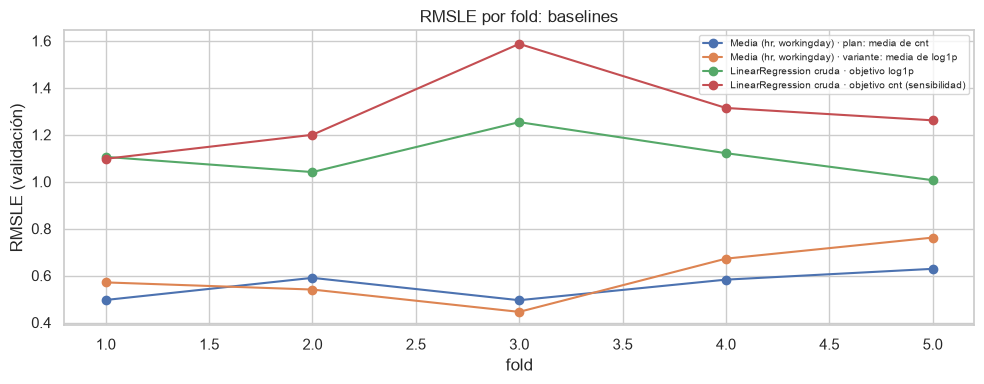

,"Media (hr, workingday) · plan: media de cnt","Media (hr, workingday) · variante: media de log1p",LinearRegression cruda · objetivo log1p,LinearRegression cruda · objetivo cnt (sensibilidad)
fold,,,,
1,0.4960,0.5708,1.1055,1.0973
2,0.5902,0.5404,1.0408,1.1997
3,0.4949,0.4453,1.2535,1.5870
4,0.5826,0.6720,1.1213,1.3139
5,0.6286,0.7616,1.0063,1.2613


In [10]:
tabla = pd.DataFrame(res).set_index("modelo")
orden = ["rmsle_media", "rmsle_std", "rmse_media", "rmse_std", "mae_media", "mae_std", "r2_media", "r2_std"]
display(tabla[orden].round(4).sort_values("rmsle_media"))

rms = pd.DataFrame({k: v["rmsle"].to_numpy() for k, v in folds.items()}, index=range(1, 6)); rms.index.name = "fold"
fig, ax = plt.subplots(figsize=(10, 4))
rms.plot(marker="o", ax=ax); ax.set_ylabel("RMSLE (validación)"); ax.set_title("RMSLE por fold: baselines")
ax.legend(fontsize=7); plt.tight_layout(); fig.savefig(FIG_DIR / "09_baselines_rmsle_por_fold.png", dpi=130, bbox_inches="tight"); plt.show()
display(rms.round(4))

### ✅ Punto de control 5

In [11]:
assert tabla.shape[0] == 4
mejor = tabla["rmsle_media"].idxmin()
print("Baseline con menor RMSLE medio de validación:", mejor, "->", round(float(tabla.loc[mejor, 'rmsle_media']), 4))
# Las cifras de la tabla provienen de los folds mostrados
for nombre in tabla.index:
    assert np.isclose(tabla.loc[nombre, "rmsle_media"], folds[nombre]["rmsle"].mean())
print("✅ La tabla coincide con la media de los folds.")

Baseline con menor RMSLE medio de validación: Media (hr, workingday) · plan: media de cnt -> 0.5585
✅ La tabla coincide con la media de los folds.


**Interpretación.** Referencia para todo lo que sigue (validación temporal, solo train):

| Baseline | RMSLE medio ± std | RMSE medio | MAE medio | R² medio |
| :--- | :---: | :---: | :---: | :---: |
| Media por `(hr, workingday)` (plan: media de `cnt`) | **0.5585 ± 0.0601** | 102.8 | 72.3 | 0.619 |
| Media por `(hr, workingday)` (variante: media de `log1p`) | 0.5980 ± 0.1221 | 113.5 | 81.4 | 0.538 |
| `LinearRegression` cruda, objetivo `log1p` | 1.1055 ± 0.0951 | 166.1 | 115.5 | −0.062 |
| `LinearRegression` cruda, objetivo `cnt` | 1.2918 ± 0.1836 | 143.2 | 105.5 | 0.205 |

1. **El baseline de calendario es el más fuerte de los dos.** Con solo 48 medias (hora × tipo de día) explica ≈ 62 % de la varianza en promedio y supera con claridad a la regresión lineal cruda. Esto concuerda con el EDA: la hora y su interacción con el tipo de día concentran la señal.
2. **La regresión lineal cruda es peor porque su forma es inadecuada, no por un error de código** (ver 5b): trata `hr`, `mnth` o `weekday` como variables numéricas lineales, mientras que la demanda por hora tiene dos picos (no monótona). Esto justifica en los datos la categoría `hr_workingday` y los modelos no lineales; aún no mide cuánto ayuda cada uno (⏳ Sprint 2).
3. **Dentro del baseline de calendario, el promedio de `cnt` supera a la variante en log** en RMSLE medio (0.5585 frente a 0.5980) y es menos inestable entre folds. Es una comparación de dos baselines y no un resultado sobre modelos finales; se conserva el del plan como referencia.
4. **El error crece en los folds 4 y 5** (RMSLE 0.583 y 0.629; R² 0.489 y 0.424, frente a R² de 0.69–0.79 en los folds 1–3). Es el síntoma que el plan anticipa por la tendencia de crecimiento (§2.4); la sección 5b lo cuantifica.

**Umbral de éxito (§2.3, ⏳ decisión del grupo):** propuesta para discutir, no decidida: tomar como referencia el RMSLE medio de **0.5585** del baseline de calendario y definir cuánta mejora relativa se exige a los modelos.

## 5b) Diagnóstico: ¿por qué fallan los baselines?
Dos comprobaciones sobre train (sin test): (1) el error del lineal **dentro de la muestra** de entrenamiento, para distinguir mala especificación de un posible error de código; (2) el sesgo del baseline por fold, comparando la demanda real de la ventana de validación con lo que el baseline predice.

In [12]:
# (1) Lineal crudo: ajuste en toda la muestra de train
from src.evaluate import ajustar, predecir_bicis
lin_full = ajustar(lineal_crudo(), X_tr, y_tr, log_target=True)
rmsle_in = rmsle(y_tr, predecir_bicis(lin_full, X_tr, log_target=True))
r2_log_in = float(lin_full.score(X_tr, np.log1p(y_tr)))
print(f"LinearRegression cruda, dentro de train: RMSLE = {rmsle_in:.4f} | R² en escala log = {r2_log_in:.4f}")

# (2) Sesgo del baseline por fold: log1p(real) - log1p(predicho); > 0 significa que el baseline subestima
filas = []
for k, (i_tr, i_va) in enumerate(cv.split(X_tr), start=1):
    m = MediaPorGrupo().fit(X_tr.iloc[i_tr], y_tr.iloc[i_tr])
    p = m.predict(X_tr.iloc[i_va]); real = y_tr.iloc[i_va].to_numpy()
    filas.append({"fold": k, "cnt real medio (val)": real.mean(), "cnt predicho medio": p.mean(),
                  "sesgo medio en log (real - pred)": float(np.mean(np.log1p(real) - np.log1p(p)))})
sesgo = pd.DataFrame(filas).set_index("fold")
display(sesgo.round(3))

LinearRegression cruda, dentro de train: RMSLE = 1.0175 | R² en escala log = 0.4779


,cnt real medio (val),cnt predicho medio,sesgo medio en log (real - pred)
fold,,,
1,172.813,138.532,0.121
2,130.628,145.572,-0.230
3,138.578,142.867,-0.186
4,232.280,142.405,0.323
5,273.033,153.858,0.512


### ✅ Punto de control 6

In [13]:
assert rmsle_in > 0.8, "el lineal crudo debería ajustar mal incluso dentro de train si el problema es de especificación"
assert np.isfinite(sesgo.to_numpy()).all()
print("✅ Diagnóstico calculado solo con datos de train.")

✅ Diagnóstico calculado solo con datos de train.


**Interpretación.**
- **Lineal crudo:** incluso ajustado y evaluado sobre la misma muestra de train, su RMSLE es 1.0175 y su R² en escala log es 0.478. Es decir, la forma lineal en variables crudas no logra describir los datos; que valide mal no se debe a un problema de partición ni de código.
- **Sesgo del baseline por fold** (tabla anterior): en los folds 1 a 3 el sesgo es pequeño y de signo variable (+0.121, −0.230, −0.186), pero en los folds 4 y 5 el baseline **subestima de forma sistemática**: la demanda real media de la ventana de validación es 232.3 y 273.0 bicicletas/hora y el baseline predice 142.4 y 153.9 (sesgo +0.323 y +0.512 en escala log). Las medias por grupo se aprenden con meses mayoritariamente de 2011, cuando la demanda era más baja (EDA, sección 7). 🔶 Esto es coherente con una tendencia de crecimiento (y con la estacionalidad: los folds 4 y 5 validan en primavera), pero este diagnóstico por sí solo no separa ambas causas; la ablación de tendencia (`yr` / `sin_yr` / `trend`) del Sprint 2 es lo que lo medirá.
- **Consecuencia para el test:** como el test (jul–dic 2012) está aún más lejos del train, hay que esperar este mismo tipo de sesgo en un modelo sin variable de tendencia; el RMSLE mensual en test (Sprint 4) lo verificará. ⏳

## 6) Siguiente sección (Sprint 2)
LightGBM sobre `log1p(cnt)` con `build_preprocessor()`, tuning con `RandomizedSearchCV` + `TimeSeriesSplit` y ablaciones. El umbral de éxito del plan (§2.3) se define a partir del RMSLE de estos baselines: ⏳ decisión del grupo.